# Aula 7 — Regressão
## Exercício: Regressão entre protótipo de sensor e instrumento de referência

**Aluno:** Leonardo Teixeira — **RA:** 245602 — Mineração de Dados (UNICAMP)

**Objetivo (enunciado da Aula 7):** realizar a regressão para os dados de um protótipo de sensor com os dados de um instrumento de referência, implementando o código e analisando a regressão com base no **R², MSE, RMSE e erro residual**, adaptando o código do exemplo de adubação e produtividade visto em aula.

**Dados:** `data/sensor_e_referencia.csv` (caminho relativo à pasta deste notebook).

**Variáveis** (como no exemplo de adubação × produtividade, a 1ª coluna do CSV é a variável independente):
- **X (independente): `referência`** — valor medido pelo instrumento de referência;
- **y (dependente): `protótipo`** — leitura do sensor protótipo, que se quer avaliar em relação à referência.

**Modelo:** regressão linear simples, protótipo = α + β · referência + erro, ajustada por mínimos quadrados (`LinearRegression` do scikit-learn).

## 1. Importação das bibliotecas

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, mean_absolute_percentage_error)

pd.set_option('display.max_columns', None)

## 2. Carregamento dos dados

In [2]:
CAMINHO_DADOS = Path("data") / "sensor_e_referencia.csv"
df = pd.read_csv(CAMINHO_DADOS, sep=",", encoding="utf-8")
df.head(10).T

,0,1,2,3,4,5,6,7,8,9
referência,"62,35364275","73,39518403","57,54010039","114,316673","114,747442","114,6822656","29,20091037","31,01720286","30,82604351","31,55015893"
protótipo,"65,00894825","86,98971566","69,02936882","109,124102","104,8253933","109,124102","39,99950462","38,41561305","39,99950462","50,86896246"


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 92 entries, 0 to 91
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   referência  92 non-null     str  
 1   protótipo   92 non-null     str  
dtypes: str(2)
memory usage: 1.6 KB


## 3. Preparação dos dados

O arquivo traz os valores no formato brasileiro (vírgula decimal), por isso as colunas são lidas como texto. Além disso, ao final da planilha existem **duas linhas que não são observações**:

- uma linha de rótulo `media,media`; e
- a linha seguinte, com as médias das colunas já calculadas (`64,46873092` / `66,30014256`).

Etapas: (1) trocar vírgula por ponto e converter para número; (2) remover a linha de rótulo `media` (vira `NaN` na conversão); (3) remover a linha de médias pré-calculadas, pois ela é um resumo da própria planilha e não uma medição.

In [4]:
df = df.replace({',': '.'}, regex=True)
df["referência"] = pd.to_numeric(df["referência"], errors="coerce")
df["protótipo"] = pd.to_numeric(df["protótipo"], errors="coerce")

# remove a linha de rotulo "media" (referencia vira NaN na conversao acima)
df.dropna(subset=["referência"], inplace=True)

# remove a ultima linha, que traz as medias das colunas ja calculadas (nao e observacao real)
df = df.iloc[:-1].copy()

print(f"Número de observações válidas: {len(df)}")
df.head(10).T

Número de observações válidas: 90


,0,1,2,3,4,5,6,7,8,9
referência,62.353643,73.395184,57.540100,114.316673,114.747442,114.682266,29.200910,31.017203,30.826044,31.550159
protótipo,65.008948,86.989716,69.029369,109.124102,104.825393,109.124102,39.999505,38.415613,39.999505,50.868962


In [5]:
df.info()

<class 'pandas.DataFrame'>
Index: 90 entries, 0 to 89
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   referência  90 non-null     float64
 1   protótipo   90 non-null     float64
dtypes: float64(2)
memory usage: 2.1 KB


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
referência,90.0,64.468731,32.839036,27.945507,35.319402,49.172302,101.355513,114.946652
protótipo,90.0,66.300143,29.114182,25.710880,40.398991,50.868962,96.582531,118.768932


**Breve análise da base:**

- não há nulos após a limpeza;
- só existem duas variáveis: `referência` (independente) e `protótipo` (dependente);
- não há valores inconsistentes (ex.: negativos, o que não faria sentido para as grandezas medidas);
- as duas variáveis têm faixas de valores parecidas (~28 a ~115 para referência, ~26 a ~119 para protótipo), o que facilita a comparação direta.

## 4. Separação das variáveis

In [7]:
# Separando os fatores/previsores da resposta/target:

x = df["referência"].values.reshape(-1, 1)
y = df["protótipo"].values.reshape(-1, 1)
print("x reshape:")
print(x)
print("y reshape:")
print(y)
# IMPORTANTE! Reshape necessário pois o scikit-learn espera arrays 2D para X.

x reshape:
[[ 62.35364275]
 [ 73.39518403]
 [ 57.54010039]
 [114.316673  ]
 [114.747442  ]
 [114.6822656 ]
 [ 29.20091037]
 [ 31.01720286]
 [ 30.82604351]
 [ 31.55015893]
 [ 38.57135761]
 [ 32.70042554]
 [ 29.6353864 ]
 [ 30.88028474]
 [ 28.53725187]
 [ 35.44896171]
 [ 35.27621481]
 [ 30.26881495]
 [ 27.94550702]
 [ 32.41129356]
 [ 35.92989673]
 [113.1112408 ]
 [114.0290134 ]
 [114.0686856 ]
 [ 36.80764067]
 [ 33.95920007]
 [ 39.20392896]
 [ 44.72470816]
 [ 69.91355859]
 [ 42.38119817]
 [113.8902441 ]
 [114.9466525 ]
 [113.0377587 ]
 [111.8585286 ]
 [112.5855165 ]
 [110.2241147 ]
 [ 78.99252951]
 [ 97.68246438]
 [ 90.02400798]
 [110.8697597 ]
 [111.1592295 ]
 [111.105718  ]
 [ 30.19124027]
 [ 34.21220753]
 [ 32.40702253]
 [ 82.62004763]
 [ 90.07590697]
 [ 82.15245098]
 [ 29.83016846]
 [ 32.23337211]
 [ 28.48253111]
 [ 42.86732848]
 [ 55.79761863]
 [ 42.02066355]
 [ 40.64528335]
 [ 49.9335601 ]
 [ 38.48345525]
 [ 46.23946741]
 [ 60.49302751]
 [ 75.8010335 ]
 [ 93.96016171]
 [103.7742085

## 5. Ajuste do modelo de regressão linear

In [8]:
regressor = LinearRegression()
regressor.fit(x, y)

y_pred = regressor.predict(x)

In [9]:
intercepto = regressor.intercept_[0]
inclinacao = regressor.coef_[0][0]
print("Intercepto (α) = {:.3f}".format(intercepto))
print("Inclinação (β) = {:.3f}".format(inclinacao))
print(f"Equação ajustada: protótipo = {intercepto:.3f} + {inclinacao:.3f} × referência")

Intercepto (α) = 11.390
Inclinação (β) = 0.852
Equação ajustada: protótipo = 11.390 + 0.852 × referência


## 6. Visualização: dispersão e reta ajustada

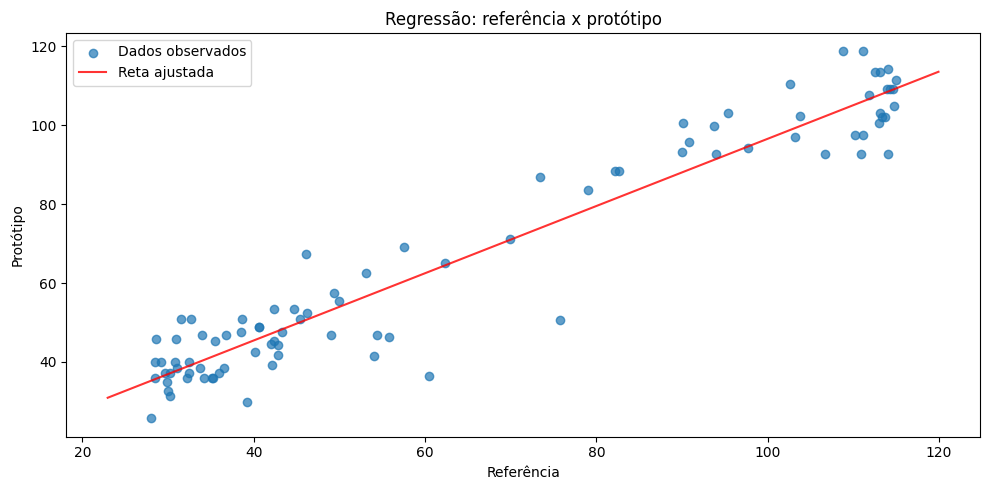

In [10]:
reta_x = np.linspace(x.min() - 5, x.max() + 5, 100).reshape(-1, 1)
reta_y = regressor.predict(reta_x)

plt.figure(figsize=(10, 5))
plt.scatter(x, y, alpha=0.7, label="Dados observados")
plt.plot(reta_x, reta_y, color="red", alpha=0.8, label="Reta ajustada")
plt.xlabel("Referência")
plt.ylabel("Protótipo")
plt.title("Regressão: referência x protótipo")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Avaliação do modelo (R², MSE, RMSE e complementares)

In [11]:
print("MSE:  {:.3f}".format(mean_squared_error(y, y_pred)))
print("RMSE: {:.3f}".format(np.sqrt(mean_squared_error(y, y_pred))))
print("MAE:  {:.3f}".format(mean_absolute_error(y, y_pred)))
print("MAPE: {:.3f}".format(mean_absolute_percentage_error(y, y_pred)))
print("R2:   {:.3f}".format(r2_score(y, y_pred)))

################################################################################
# Calculo do R2 ajustado:
def r2_ajustado(x, y, y_pred):
    """
    r2_ajustado retorna o R2 Ajustado e recebe como argumento as series com o
    valor alvo e o predito.
    """
    n = x.shape[0]
    k = x.shape[1]
    return (1 - ((n - 1) / (n - (k + 1))) * (1 - r2_score(y, y_pred)))
################################################################################

print("R2 Ajustado: {:.3f}".format(r2_ajustado(x, y, y_pred)))

MSE:  64.579
RMSE: 8.036
MAE:  6.139
MAPE: 0.110
R2:   0.923
R2 Ajustado: 0.922


**Interpretação das métricas**

- **R² = 0,923** (R² ajustado = 0,922): proporção da variância das leituras do protótipo explicada pela reta. 92,3% da variação do protótipo acompanha linearmente a referência; o restante é dispersão em torno da reta. Com um único previsor, o R² ajustado praticamente coincide com o R².
- **MSE = 64,579**: média dos quadrados dos resíduos. Está em unidades ao quadrado e penaliza fortemente os erros grandes, então serve mais para comparar modelos do que para leitura direta.
- **RMSE = 8,036**: raiz do MSE, na mesma unidade das leituras. É o tamanho típico do erro da reta: cerca de 8,6% da amplitude das leituras do protótipo nesta base (25,7 a 118,8) e 12% da sua média (66,3).
- **MAE = 6,139** e **MAPE = 0,110 (11%)**, complementares: erro absoluto médio e erro percentual médio. O RMSE maior que o MAE indica alguns erros grandes, que o quadrado do MSE/RMSE penaliza mais; isso é investigado na análise de resíduos a seguir.

As métricas foram calculadas sobre os mesmos 90 pontos usados no ajuste (não há conjunto de teste separado, como no exemplo de aula). Elas descrevem a qualidade do ajuste, não o desempenho em dados novos.

## 8. Análise do erro residual

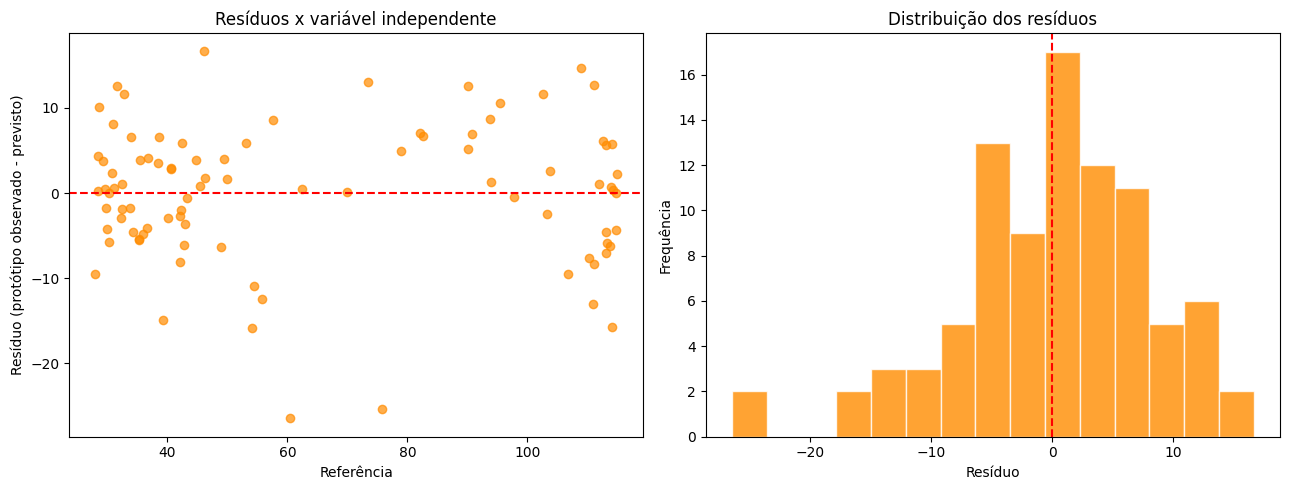

In [12]:
residuos = y - y_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(x, residuos, alpha=0.7, color="darkorange")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Referência")
axes[0].set_ylabel("Resíduo (protótipo observado - previsto)")
axes[0].set_title("Resíduos x variável independente")

axes[1].hist(residuos, bins=15, color="darkorange", alpha=0.8, edgecolor="white")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Resíduo")
axes[1].set_ylabel("Frequência")
axes[1].set_title("Distribuição dos resíduos")

plt.tight_layout()
plt.show()

In [13]:
# Diagnóstico quantitativo dos resíduos (complementa a leitura visual acima)
n = len(y)
erro_padrao_regressao = np.sqrt(np.sum(residuos ** 2) / (n - 2))   # s = sqrt(SSE / (n - 2))
residuos_padronizados = residuos.flatten() / erro_padrao_regressao
n_acima_2 = int((np.abs(residuos_padronizados) > 2).sum())
n_acima_3 = int((np.abs(residuos_padronizados) > 3).sum())

print(f"Erro-padrão da regressão s = {erro_padrao_regressao:.3f}")
print(f"Observações com |resíduo padronizado| > 2: {n_acima_2} de {n} ({100 * n_acima_2 / n:.1f}%)")
print(f"Observações com |resíduo padronizado| > 3: {n_acima_3} de {n} ({100 * n_acima_3 / n:.1f}%)")

print("\n3 maiores resíduos em módulo:")
for idx in np.argsort(-np.abs(residuos_padronizados))[:3]:
    print(f"  referência={x[idx, 0]:6.2f} | protótipo={y[idx, 0]:6.2f} | previsto={y_pred[idx, 0]:6.2f} | "
          f"resíduo={residuos[idx, 0]:6.2f} | padronizado={residuos_padronizados[idx]:5.2f}")

# dispersão dos resíduos nas duas metades do eixo x (indício de variância não constante)
elevados = np.abs(residuos_padronizados) > 3
mediana_x = float(np.median(x))
metade_baixa = x.flatten() < mediana_x
res = residuos.flatten()
print(f"\nDesvio padrão dos resíduos, referência < {mediana_x:.1f}:  {res[metade_baixa].std():.3f} (n={metade_baixa.sum()})")
print(f"Desvio padrão dos resíduos, referência >= {mediana_x:.1f}: {res[~metade_baixa].std():.3f} (n={(~metade_baixa).sum()})")
print(f"  idem, sem as {elevados.sum()} observações com |padronizado| > 3: "
      f"{res[~metade_baixa & ~elevados].std():.3f} (n={(~metade_baixa & ~elevados).sum()})")
print(f"Correlação entre |resíduo| e referência: {np.corrcoef(np.abs(res), x.flatten())[0, 1]:.3f}")

# sensibilidade do ajuste às observações com |resíduo padronizado| > 3
regressor_sem = LinearRegression().fit(x[~elevados], y[~elevados])
pred_sem = regressor_sem.predict(x[~elevados])
print(f"\nSem as {elevados.sum()} observações com |padronizado| > 3: "
      f"β = {regressor_sem.coef_[0][0]:.3f} (com todas: {inclinacao:.3f}) | "
      f"R² = {r2_score(y[~elevados], pred_sem):.3f} (com todas: {r2_score(y, y_pred):.3f}) | "
      f"MSE = {mean_squared_error(y[~elevados], pred_sem):.3f} (com todas: {mean_squared_error(y, y_pred):.3f})")

Erro-padrão da regressão s = 8.127
Observações com |resíduo padronizado| > 2: 3 de 90 (3.3%)
Observações com |resíduo padronizado| > 3: 2 de 90 (2.2%)

3 maiores resíduos em módulo:
  referência= 60.49 | protótipo= 36.43 | previsto= 62.91 | resíduo=-26.48 | padronizado=-3.26
  referência= 75.80 | protótipo= 50.53 | previsto= 75.95 | resíduo=-25.42 | padronizado=-3.13
  referência= 46.15 | protótipo= 67.37 | previsto= 50.69 | resíduo= 16.67 | padronizado= 2.05

Desvio padrão dos resíduos, referência < 49.2:  6.070 (n=45)
Desvio padrão dos resíduos, referência >= 49.2: 9.596 (n=45)
  idem, sem as 2 observações com |padronizado| > 3: 8.026 (n=43)
Correlação entre |resíduo| e referência: 0.142

Sem as 2 observações com |padronizado| > 3: β = 0.854 (com todas: 0.852) | R² = 0.940 (com todas: 0.923) | MSE = 50.380 (com todas: 64.579)


### Leitura dos resíduos segundo os padrões da Aula 7

A análise de resíduos é **diagnóstica**: indica se as suposições do modelo linear parecem razoáveis, mas gráficos e indicadores simples não provam nem descartam um problema. Por isso, abaixo só se afirma o que os dados mostram com clareza; indícios fracos são descritos como tais. A Aula 7 apresenta cinco padrões de referência:

- **"Ideal" (faixa horizontal de largura aproximadamente constante em torno de zero):** é o padrão mais próximo do observado. Os resíduos se distribuem dos dois lados de zero ao longo de toda a faixa de referência. O histograma é aproximadamente simétrico em torno de zero, com uma cauda à esquerda formada por poucos resíduos negativos grandes.
- **σ² não constante (heterocedasticidade):** indício fraco, não demonstrado. O desvio padrão dos resíduos é maior na metade superior da referência (9,596 × 6,070 na metade inferior). Parte dessa diferença vem das duas observações com resíduos padronizados elevados, e sem elas o valor cai para 8,026. A correlação entre |resíduo| e referência é baixa (0,142), e o gráfico não mostra o formato de "leque" do slide. Confirmar heterocedasticidade exigiria um teste formal (ex.: Breusch-Pagan), que não foi feito aqui.
- **Não linearidade:** o gráfico não mostra curvatura sistemática ("arco"). Ressalva: as referências se concentram em dois grupos (≈ 28–60 e ≈ 90–115). A faixa intermediária tem poucas observações e é justamente onde estão os maiores resíduos negativos. Com tão poucos pontos nessa faixa, não é possível avaliar bem a forma da relação ali.
- **"Outlier":** 2 das 90 observações (referência ≈ 60,5 e ≈ 75,8) têm **resíduos padronizados elevados** (−3,26 e −3,13, usando s = √(SSE/(n−2))). Nelas, o protótipo leu 26,5 e 25,4 unidades abaixo do previsto. O critério |resíduo padronizado| > 3 é uma regra prática de triagem, não um teste formal, por isso elas são tratadas como observações a investigar, não como erros a descartar. Removê-las quase não altera a reta (β = 0,854 sem elas, 0,852 com elas), ou seja, elas têm pouca influência sobre os coeficientes. O R² (0,940) e o MSE (50,380) mudam principalmente porque os próprios erros grandes delas deixam de entrar no cálculo. Como não há informação que indique erro de medição, elas foram mantidas no modelo.
- **Não independência (padrão ao longo do tempo):** não avaliável. O CSV não informa a ordem nem o momento das medições.

## 9. Conclusão

- **Equação ajustada:** protótipo = 11,390 + 0,852 × referência.
- **Qualidade do ajuste:** R² = 0,923 (R² ajustado = 0,922), MSE = 64,579 e RMSE = 8,036. O erro típico é de ≈ 8 unidades, cerca de 8,6% da amplitude das leituras. Há uma relação linear forte entre o protótipo e o instrumento de referência.
- **Viés do protótipo:** como β = 0,852 < 1 e α = 11,390 > 0, o protótipo tende a ler **acima** da referência nos valores baixos e **abaixo** nos valores altos. Pela reta ajustada, as duas leituras coincidem em referência ≈ 77, dado por α / (1 − β). Esse erro é sistemático e pode ser corrigido por calibração. Invertendo a reta, referência ≈ (protótipo − 11,390) / 0,852; é uma estimativa aproximada, pois a reta foi ajustada para prever o protótipo a partir da referência.
- **Resíduos:** entre os padrões da Aula 7, o mais próximo é o "ideal", com as seguintes observações:
  - há indício fraco, não demonstrado, de variância maior na metade superior da referência;
  - não aparece curvatura sistemática, mas a faixa intermediária (≈ 60–90) tem poucas observações;
  - duas observações têm resíduos padronizados elevados (≈ −3,2), com pouca influência sobre a reta;
  - a independência não pode ser avaliada sem a ordem das medições.

**Em resumo:** o protótipo acompanha linearmente o instrumento de referência (R² = 0,923), com erro típico de ≈ 8 unidades e um viés sistemático corrigível por calibração linear. Os resíduos não indicam violação clara das suposições do modelo, mas a amostra pequena na faixa intermediária e as duas leituras muito abaixo do previsto merecem verificação experimental.

**Dados:** o arquivo tem 92 linhas. Duas delas não são medições (o rótulo `media` e as médias pré-calculadas) e foram removidas, restando **90 observações** usadas no ajuste.